In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


 Star    B-V  B-V error    V-R  V-R error
    1 0.6828     0.0026 0.1522     0.0021
    2 0.6136     0.0020 0.1094     0.0017
    3 0.9905     0.0014 0.2759     0.0010
    4 1.0064     0.0014 0.2478     0.0010
    5 0.7881     0.0027 0.1967     0.0020
    6 1.1382     0.0017 0.3931     0.0011
    7 1.0352     0.0017 0.3327     0.0011
    8 0.8180     0.0016 0.2447     0.0012
    9 0.8167     0.0032 0.1965     0.0024
   12 0.9010     0.0047 0.2628     0.0033


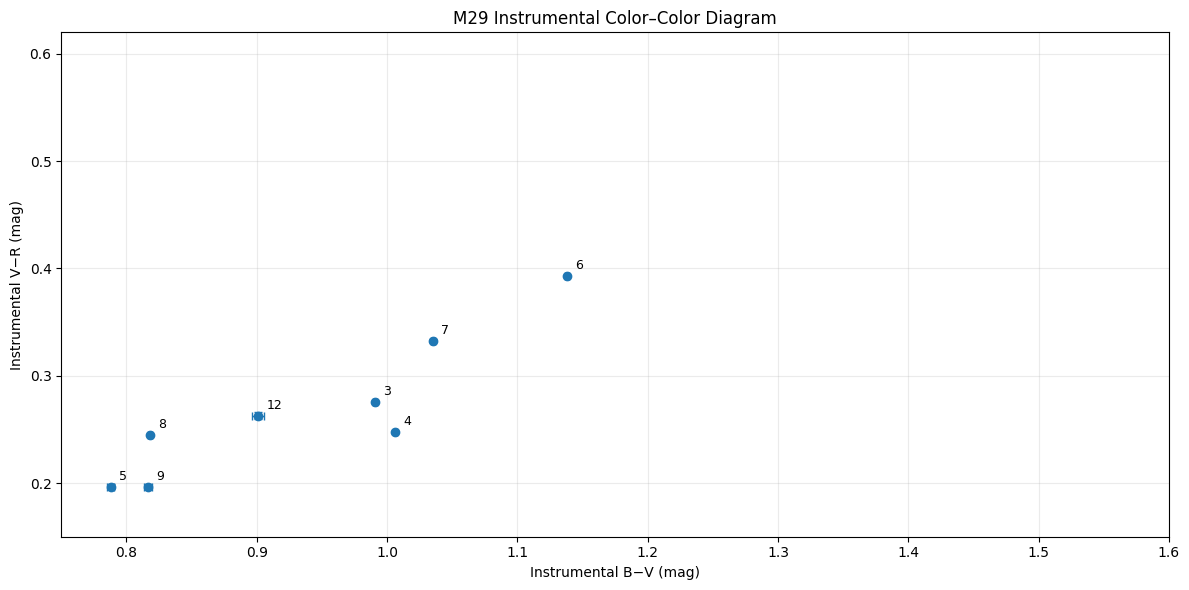

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = DATA/'M29.csv'
df = pd.read_csv(csv_path)
# AstroImageJ stack order: B, R, V
b, r, v = df.iloc[0], df.iloc[1], df.iloc[2]
star_ids = [1, 2, 3, 4, 5, 6, 7, 8, 9, 12]

rows = []
for star in star_ids:
    suffix = 'T1' if star == 1 else f'C{star}'
    C_B, C_R, C_V = (float(row[f'Source-Sky_{suffix}']) for row in (b, r, v))
    E_B, E_R, E_V = (float(row[f'Source_Error_{suffix}']) for row in (b, r, v))
    bv = -2.5 * np.log10(C_B / C_V)
    vr = -2.5 * np.log10(C_V / C_R)
    k = 2.5 / np.log(10)
    bv_err = k * np.hypot(E_B / C_B, E_V / C_V)
    vr_err = k * np.hypot(E_V / C_V, E_R / C_R)
    rows.append((star, bv, bv_err, vr, vr_err))

results = pd.DataFrame(rows, columns=['Star', 'B-V', 'B-V error', 'V-R', 'V-R error'])
results.to_csv(OUT/'m29_instrumental_colors.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 6))
ax.errorbar(results['B-V'], results['V-R'],
            xerr=results['B-V error'], yerr=results['V-R error'],
            fmt='o', capsize=3, markersize=6, linewidth=1, label='M29 stars')
for _, row in results.iterrows():
    ax.annotate(str(int(row['Star'])), (row['B-V'], row['V-R']),
                xytext=(6, 5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Instrumental B−V (mag)', ylabel='Instrumental V−R (mag)',
       title='M29 Instrumental Color–Color Diagram')
ax.set_xlim(0.75, 1.60)
ax.set_ylim(0.15, 0.62)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig('m29_color_color.pdf', bbox_inches='tight')
fig.savefig('m29_color_color.png', dpi=220, bbox_inches='tight')
print(results.round(4).to_string(index=False))